# Week 7 — Lab: K-means Clustering and PCA

**Course 04224 · Programming for Artificial Intelligence and Data Science**
Hung Vuong University, Ho Chi Minh City · Faculty of Engineering and Technology

**Learning outcomes:** CLO5; CLO4 — communicate and visualize results.
**Duration:** 3 periods, about **150 minutes**. Synthetic teaching data are read
from `../lab_data/khachhang.csv`; no network is needed after installing libraries.

**Plan:** 1. Scale (30′) · 2. Choose k (40′) · 3. Cluster profiles (35′) · 4. PCA (45′).

**Submit:** rename to `Week07_Lab_<StudentID>.ipynb`.
Complete every `# TODO`, **Restart & Run All**, and keep outputs and figures.
Include the k-selection table/plots, cluster profiles, PCA variance curve, 2D projection and interpretation.

## Before you start
Start Jupyter in `lab_exercises/`. Use `random_state=42` and run cells in order.
Each `# TODO` is explained in the preceding text. Replace `...` with your code.
Shape, probability and data-integrity checks must pass; model scores are observations,
not targets to force your answer to match. Rankings and timings can vary by version/hardware.

Customer data: `thang_gan_nhat` = months since the last order;
`tong_chi_tieu` = total spending (VND); `so_don` = order count;
`so_ticket_ho_tro` = support-ticket count. `roi_bo=1` means churn.
`ma_kh` is an identifier; categorical `kenh_ua_thich` and `tinh_tp` are outside
this lab's scope. Keep both the label and identifier out of the feature matrix.

In [1]:
import sys
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
FEATURES = ["thang_gan_nhat", "tong_chi_tieu", "so_don", "so_ticket_ho_tro"]
DATA_DIR = Path("../lab_data")
if not (DATA_DIR / "khachhang.csv").is_file():
    raise FileNotFoundError(f"Start Jupyter in lab_exercises/. Current folder: {Path.cwd()}")
customers = pd.read_csv(DATA_DIR / "khachhang.csv")
assert customers.shape == (1500, 8)
assert customers["ma_kh"].is_unique
assert not customers[FEATURES + ["roi_bo"]].isna().any().any()
X = customers[FEATURES].copy()
y = customers["roi_bo"].copy()
print("Python:", sys.version.split()[0], "| numpy:", np.__version__,
      "| pandas:", pd.__version__, "| sklearn:", sklearn.__version__)
print("Shape:", X.shape, "| churn fraction:", round(y.mean(), 4))
print(customers[FEATURES].describe().round(2).to_string())

from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons

Python: 3.13.5 | numpy: 2.1.3 | pandas: 2.2.3 | sklearn: 1.6.1
Shape: (1500, 4) | churn fraction: 0.2087
       thang_gan_nhat  tong_chi_tieu   so_don  so_ticket_ho_tro
count         1500.00        1500.00  1500.00           1500.00
mean            14.20     7793408.00     5.98              1.48
std              6.84     4637241.09     2.45              1.13
min              0.00      222000.00     0.00              0.00
25%              9.40     4382250.00     4.00              0.00
50%             14.30     6947500.00     6.00              1.00
75%             18.90    10196500.00     8.00              2.00
max             39.20    34434000.00    19.00              3.00


## Task 1 — Distance and units (30 min)
This is an **exploratory description of the 1500 current customers**, not a future
prediction benchmark. Fit scaler/PCA on all X here. If PCA is used before a predictive
model elsewhere, fit it inside the training split/fold.
Never use `roi_bo` to fit or select k; churn labels are not segmentation ground truth.
**1.1** Fit `StandardScaler` on the four numeric features and obtain `Z`; check mean/std.
**1.2** For `k=4, n_init=10`, fit K-means on raw X and Z. Compare silhouettes
**both measured in Z** for a shared geometry. Change VND to million VND and fit a third raw model.
Compare partitions with adjusted Rand index (ARI), not direct equality of cluster IDs.

In [2]:
# TODO 1.1
scaler = StandardScaler()
Z = scaler.fit_transform(X)
assert Z.shape == (1500, 4)
assert np.allclose(Z.mean(axis=0), 0, atol=1e-10)
assert np.allclose(Z.std(axis=0), 1, atol=1e-10)
print("Raw feature SD:", X.std(ddof=0).to_dict())

# TODO 1.2
raw_km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X)
scaled_km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(Z)
X_million = X.copy()
X_million["tong_chi_tieu"] /= 1_000_000
million_km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_million)
for name, labels in [("raw VND", raw_km.labels_), ("standardized", scaled_km.labels_),
                     ("raw million VND", million_km.labels_)]:
    print(name, "silhouette in Z:", round(silhouette_score(Z, labels, sample_size=1000,
                                                         random_state=RANDOM_STATE), 4))
print("ARI raw VND vs raw million VND:", adjusted_rand_score(raw_km.labels_, million_km.labels_))
print("ARI raw VND vs standardized:", adjusted_rand_score(raw_km.labels_, scaled_km.labels_))

Raw feature SD: {'thang_gan_nhat': 6.8405950030355855, 'tong_chi_tieu': 4635695.081596286, 'so_don': 2.44777449941778, 'so_ticket_ho_tro': 1.1320000000000088}


c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

raw VND silhouette in Z: 0.059
standardized silhouette in Z: 0.2082
raw million VND silhouette in Z: 0.1222
ARI raw VND vs raw million VND: 0.13838923382326287
ARI raw VND vs standardized: 0.12958345013713857


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


**Write 1:** which column dominates raw distances? Does changing units change information? Why are inertias from different unit systems not directly comparable?
- Cột `tong_chi_tieu` chi phối hoàn toàn. Lý do là độ lệch chuẩn của cột này rất lớn (lên tới ~4,635,695 VND), trong khi các cột `thang_gan_nhat`, `so_don`, và `so_ticket_ho_tro` có biên độ dao động rất nhỏ (chỉ từ 1 đến vài đơn vị). Do đó, khoảng cách Euclid bị thống trị bởi tổng chi tiêu.
  
- Không làm thay đổi bản chất thông tin, nhưng nó làm thay đổi cấu trúc không gian hình học khoảng cách. Vì K-means phân cụm dựa vào khoảng cách, việc thay đổi đơn vị (ví dụ đổi VND sang triệu VND) mà không chuẩn hóa sẽ dẫn đến kết quả phân cụm khác hẳn.
  
- Inertia là tổng bình phương khoảng cách (SSE). Khi thay đổi đơn vị (chia chi tiêu cho 1.000.000), các giá trị khoảng cách bị thu nhỏ, dẫn đến giá trị inertia thay đổi theo bình phương tỷ lệ đó, nên không thể dùng để so sánh trực tiếp giữa các hệ thống đơn vị khác nhau.

## Task 2 — Choose k with evidence (40 min)
**2.1** Sweep `k=2..8`, `n_init=10`, seed 42 on Z. Store the model, inertia and silhouette
(`sample_size=1000`, seed 42). Plot elbow and silhouette in separate panels with separate y axes.
**2.2** Suggest k by the highest silhouette, then set `chosen_k` using your own argument
(use the suggestion by default). Consider separation, cluster sizes and the intended use.
Inertia usually decreases with k, so the largest k is not automatically best. There is no hidden “correct” k.

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

 k   inertia  silhouette
 2 4790.2406      0.2171
 3 4065.9802      0.2173
 4 3515.6035      0.2082
 5 3065.3098      0.2088
 6 2778.2419      0.2042
 7 2569.7911      0.2124
 8 2416.2696      0.2099


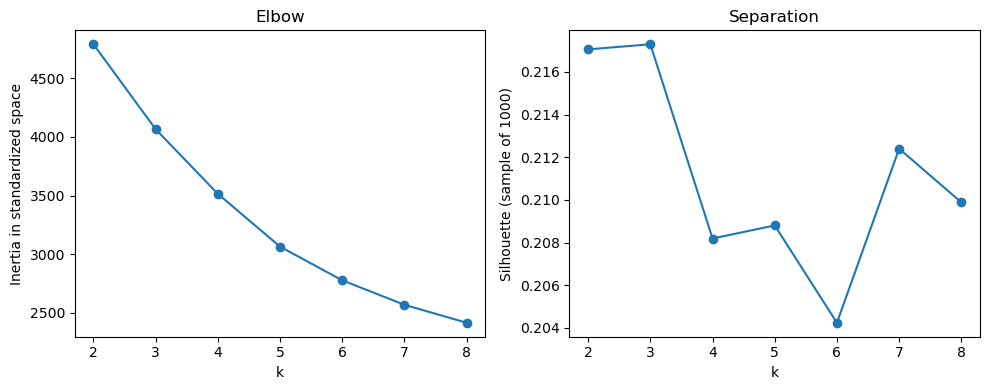

Suggested: 3 | chosen: 3
Cluster sizes: {0: 601, 1: 296, 2: 603}


In [3]:
# TODO 2.1
cluster_models, k_rows = {}, []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    cluster_models[k] = km
    k_rows.append({
        "k": k, 
        "inertia": km.inertia_, 
        "silhouette": silhouette_score(Z, km.labels_, sample_size=1000, random_state=RANDOM_STATE)
    })

k_table = pd.DataFrame(k_rows)
print(k_table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(k_table["k"], k_table["inertia"], "o-")
axes[0].set(xlabel="k", ylabel="Inertia in standardized space", title="Elbow")

axes[1].plot(k_table["k"], k_table["silhouette"], "o-")
axes[1].set(xlabel="k", ylabel="Silhouette (sample of 1000)", title="Separation")
plt.tight_layout()
plt.show()

suggested_k = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])

# TODO 2.2 — use suggested_k or justify another k from 2..8 in your written answer.
chosen_k = suggested_k
assert chosen_k in cluster_models
chosen = cluster_models[chosen_k]
labels = chosen.labels_
print("Suggested:", suggested_k, "| chosen:", chosen_k)
print("Cluster sizes:", pd.Series(labels).value_counts().sort_index().to_dict())

**Write 2:** defend k and one plausible alternative. If silhouette is low, should the groups be advertised as clearly separated natural customer types?
- Dựa trên biểu đồ hệ số Silhouette, giá trị k = 3 được hệ thống gợi ý và lựa chọn (chosen_k = 3) vì đạt điểm số phân tách cao nhất (~0.2173), đồng thời chia dữ liệu thành 3 nhóm có quy mô cân bằng hợp lý (601, 296 và 603 khách hàng). 
- Một phương án thay thế hợp lý là k = 2 (đạt điểm silhouette xấp xỉ ~0.2171) hoặc k = 7 (nếu doanh nghiệp muốn chia nhỏ khách hàng thành nhiều phân khúc chi tiết hơn để phục vụ chiến dịch marketing chuyên sâu). Tuy nhiên, k = 3 là lựa chọn tối ưu vì giữ được tính cô đặc và dễ giải thích chân dung khách hàng nhất.
  
- Không nên. Hệ số Silhouette quanh mức 0.21 là khá thấp (nằm trong vùng cấu trúc yếu hoặc có hiện tượng chồng lấn). Điều này chứng minh rằng ranh giới giữa các cụm không thực sự rõ rệt hay cách biệt tuyệt đối, mà chúng chỉ là các vùng mật độ khác nhau trong không gian dữ liệu liên tục. Do đó, doanh nghiệp chỉ nên xem đây là các nhóm hành vi mang tính tham khảo để định hướng dịch vụ, chứ không phải các phân khúc tự nhiên độc lập hoàn toàn.

## Task 3 — Turn cluster IDs into customer profiles (35 min)
**3.1** Group customers by cluster: report count and means of all four features in
**original units**. Inverse-transform the fitted centroids and compare with group means.
Measure the gap in standard deviations so features with different units are comparable.
Do not require exact equality: stopping at `tol` or `max_iter` can leave fitted centroids
slightly different from the means of the final assigned groups.
**3.2** Draw a standardized-centroid heatmap with feature labels, colorbar and a symmetric
color scale centered at zero. Give each cluster a descriptive name and propose an action to validate.
**3.3** Refit the same k with seed 7, `n_init=10`; report ARI against seed 42.
One alternate seed is an initial stability check, not proof of clustering quality.

         thang_gan_nhat  tong_chi_tieu  so_don  so_ticket_ho_tro    n
cluster                                                              
0                 13.88     5865667.22    6.00              0.45  601
1                 13.53    15005875.00    6.08              1.39  296
2                 14.85     6174306.80    5.91              2.54  603
Largest centroid / assigned-group-mean gap (standard deviations): 0.0


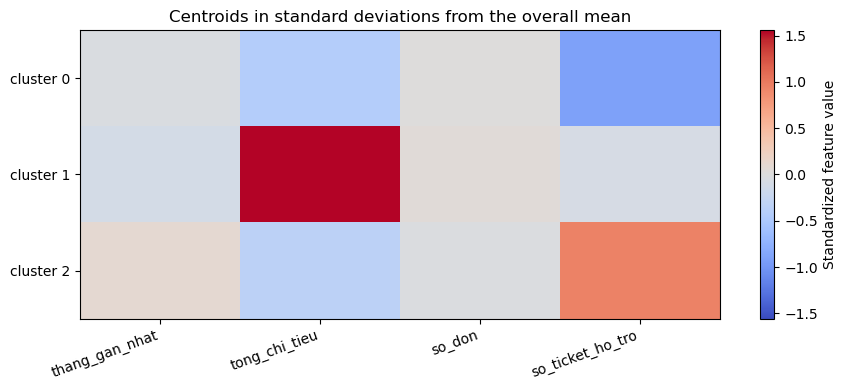

Stability ARI (42 vs 7): 1.0


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


In [4]:
# TODO 3.1
profile_data = X.assign(cluster=labels)
profile = profile_data.groupby("cluster")[FEATURES].mean()
counts = profile_data.groupby("cluster").size().rename("n")
centers_original = pd.DataFrame(scaler.inverse_transform(chosen.cluster_centers_), columns=FEATURES)
print(profile.join(counts).round(2).to_string())
assert counts.sum() == len(X)
assert profile.shape == centers_original.shape == (chosen_k, len(FEATURES))
assert np.isfinite(profile.to_numpy()).all() and np.isfinite(centers_original.to_numpy()).all()
# Tolerance-based stopping can leave a small gap; report it instead of asserting equality.
centroid_gap_sd = np.abs((profile.to_numpy() - centers_original.to_numpy()) / scaler.scale_).max()
print("Largest centroid / assigned-group-mean gap (standard deviations):", round(float(centroid_gap_sd), 6))

# TODO 3.2
fig, ax = plt.subplots(figsize=(9, 4))
limit = max(1.0, float(np.abs(chosen.cluster_centers_).max()))
im = ax.imshow(chosen.cluster_centers_, cmap="coolwarm", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=20, ha="right")
ax.set_yticks(range(chosen_k), [f"cluster {i}" for i in range(chosen_k)])
ax.set_title("Centroids in standard deviations from the overall mean")
fig.colorbar(im, ax=ax, label="Standardized feature value")
plt.tight_layout()
plt.show()

# TODO 3.3
alternate = KMeans(n_clusters=chosen_k, n_init=10, random_state=7).fit(Z)
print("Stability ARI (42 vs 7):", adjusted_rand_score(labels, alternate.labels_))

**Write 3:** name clusters from the profile table and include units. Why does cluster 0 not mean “good customer”? Why does naming establish no causal relationship?
- Cụm 0 (n = 601 — Nhóm khách hàng tiêu chuẩn / phổ thông): Có thời gian từ đơn hàng gần nhất trung bình 13.88 tháng, tổng chi tiêu trung bình khoảng 5,865,672 VND, số lượng đơn hàng trung bình là 6.00 đơn, và số phiếu hỗ trợ rất thấp (~0.45 phiếu).
- Cụm 1 (n = 296 — Nhóm khách hàng VIP / chi tiêu cao): Có thời gian từ đơn hàng gần nhất trung bình 13.53 tháng, tổng chi tiêu rất cao lên tới khoảng 15,005,875 VND, số lượng đơn hàng trung bình ~6.08 đơn, và số phiếu hỗ trợ trung bình khoảng 1.39 phiếu.
- Cụm 2 (n = 603 — Nhóm khách hàng hay gặp sự cố / cần hỗ trợ): Có thời gian từ đơn hàng gần nhất trung bình 14.85 tháng, tổng chi tiêu trung bình khoảng 6,174,307 VND, số lượng đơn hàng ~5.91 đơn, đặc biệt có số lượng phiếu hỗ trợ cực kỳ cao (~2.54 phiếu).

- Thuật toán phân cụm K-means không hề biết gì về mục tiêu kinh doanh hay nhãn rời bỏ (`roi_bo`); nó chỉ gom nhóm dựa trên khoảng cách hình học giữa các đặc trưng hành vi. Cụm 0 chỉ phản ánh một nhóm khách hàng có hành vi chi tiêu ở mức trung bình phổ thông và ít tạo phiếu hỗ trợ, chứ không đồng nghĩa với việc họ là "khách hàng tốt" (ví dụ: họ có thể ít mua sắm lặp lại hoặc mang lại lợi nhuận thấp cho doanh nghiệp).

- Việc đặt tên cho các cụm (như "VIP", "Phổ thông", "Hay gặp sự cố") chỉ là nhãn mô tả định tính do con người tự áp đặt dựa trên số liệu trung bình thống kê sau khi đã gom cụm xong. K-means chỉ tìm ra các vùng mật độ khoảng cách trong không gian dữ liệu chứ không giải thích được nguyên nhân gốc rễ vì sao khách hàng lại hành động như vậy, do đó hoàn toàn không chứng minh được quan hệ nhân quả.

## Task 4 — PCA: compression and visualization (45 min)
**4.1** Fit full PCA (`svd_solver='full'`) on Z. Plot cumulative variance and a 95% line.
Find `n95`: the first index reaching 0.95 plus one. Four weakly correlated features may
require all four components; PCA does not promise dimensionality reduction at 95%.
**4.2** Fit `PCA(n_components=0.95, svd_solver='full')` and check the output width. Print
the first two loading rows. These combine **standardized features**; component signs may flip across versions.
**4.3** Project Z onto two PCs, colored by the **existing 4D cluster labels**. Do not refit
K-means in 2D. Label axes with explained-variance percentages. Compute 2-PC reconstruction MSE in Z space.
**Write 4:** how much variance does the plot retain? Does overlap in 2D prove that clusters
are identical in 4D? Does PCA optimize silhouette or label separation?
- Biểu đồ chiếu 2D (PC1 và PC2) giữ lại được tổng cộng khoảng 51.04% tổng phương sai của dữ liệu gốc (trong đó PC1 giữ ~25.69% và PC2 giữ ~25.35%). Để đạt được mức 95% phương sai tích lũy, hệ thống cần dùng đến toàn bộ 4 thành phần chính (n95 = 4).

- Không. Việc các cụm có hiện tượng chồng lấn lên nhau trên không gian 2D chỉ là hệ quả của việc mất mát thông tin (mất gần 49% phương sai) khi nén từ 4 chiều xuống 2 chiều. Các điểm dữ liệu thực chất phân tách rõ ràng hơn rất nhiều trong không gian 4 chiều ban đầu mà thuật toán K-means đã sử dụng để gom cụm.

- Không. PCA là phương pháp không giám sát nhằm tối đa hóa phương sai của dữ liệu tuyến tính, hoàn toàn không biết gì về nhãn cụm hay việc tối ưu hóa hệ số Silhouette / độ tách biệt giữa các nhóm.

Explained ratios: [0.2569 0.2535 0.25   0.2396]
n95: 4 | shape: (1500, 4)
     thang_gan_nhat  tong_chi_tieu  so_don  so_ticket_ho_tro
PC1          0.4677        -0.0659 -0.4888            0.7335
PC2         -0.6173         0.6493 -0.4053            0.1818


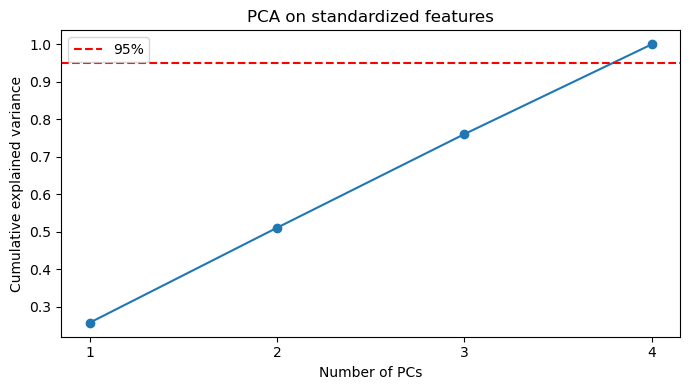

In [5]:
# TODO 4.1–4.2
pca = PCA(svd_solver="full").fit(Z)
cumulative = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.where(cumulative >= 0.95)[0][0]) + 1
pca95 = PCA(n_components=0.95, svd_solver="full").fit(Z)
compressed = pca95.transform(Z)
assert compressed.shape == (1500, n95)
assert cumulative[n95 - 1] >= 0.95
print("Explained ratios:", pca.explained_variance_ratio_.round(4))
print("n95:", n95, "| shape:", compressed.shape)
print(pd.DataFrame(pca.components_[:2], columns=FEATURES, index=["PC1", "PC2"]).round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 5), cumulative, "o-")
ax.axhline(0.95, color="red", ls="--", label="95%")
ax.set(xlabel="Number of PCs", ylabel="Cumulative explained variance", title="PCA on standardized features", xticks=range(1, 5))
ax.legend()
plt.tight_layout()
plt.show()

2D retained variance: 0.5103913873086374
2D reconstruction MSE in Z: 0.48960861269136224


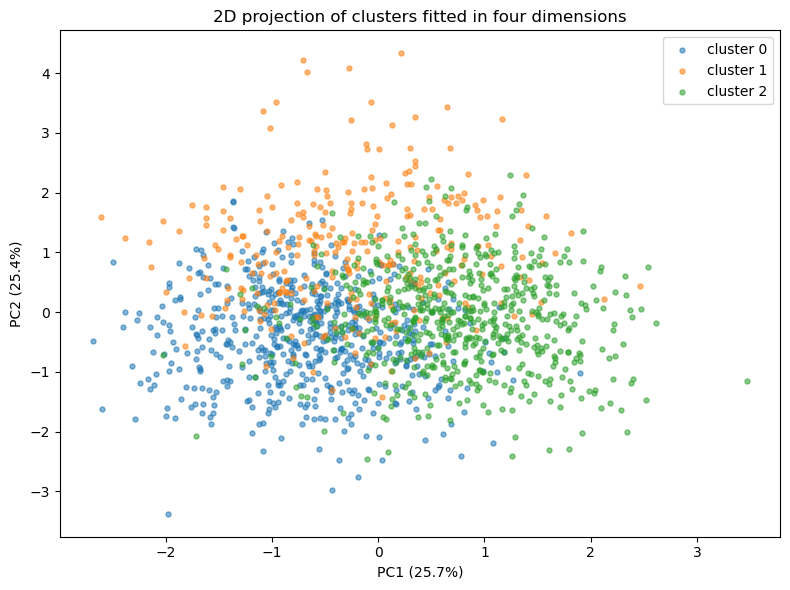

In [6]:
# TODO 4.3
pca2 = PCA(n_components=2, svd_solver="full")
projection = pca2.fit_transform(Z)
reconstructed = pca2.inverse_transform(projection)
reconstruction_mse = np.mean((Z - reconstructed) ** 2)
print("2D retained variance:", pca2.explained_variance_ratio_.sum())
print("2D reconstruction MSE in Z:", reconstruction_mse)
fig, ax = plt.subplots(figsize=(8, 6))
for cluster_id in range(chosen_k):
    mask = labels == cluster_id
    ax.scatter(projection[mask, 0], projection[mask, 1], s=13, alpha=0.55, label=f"cluster {cluster_id}")
ax.set(xlabel=f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})",
       ylabel=f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})",
       title="2D projection of clusters fitted in four dimensions")
ax.legend()
plt.tight_layout()
plt.show()
assert projection.shape == (1500, 2)
assert np.isfinite(reconstruction_mse) and reconstruction_mse >= 0

## Stretch — When cluster shape defeats K-means (optional)
Generate `make_moons(n_samples=500, noise=0.06, random_state=42)`. Compare K-means k=2
with DBSCAN `eps=0.2, min_samples=5`. Plot partitions with matching axes.
Use synthetic truth only to compute ARI **after fitting**, never to choose eps.
DBSCAN label −1 means noise, not a customer segment.

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


K-Means (k=2) noise rows: 0
DBSCAN (eps=0.2) noise rows: 0


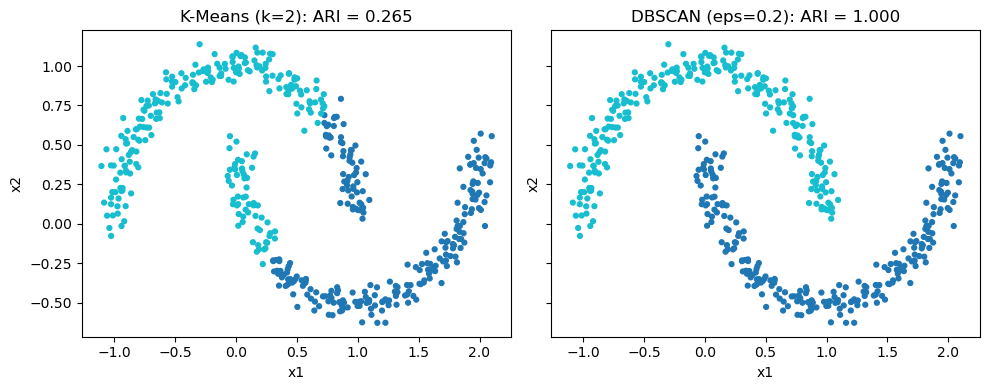

In [7]:
# TODO — optional stretch
moons, truth = make_moons(n_samples=500, noise=0.06, random_state=RANDOM_STATE)
moon_models = {
    "K-Means (k=2)": KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE),
    "DBSCAN (eps=0.2)": DBSCAN(eps=0.2, min_samples=5)
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, (name, estimator) in zip(axes, moon_models.items()):
    assigned = estimator.fit_predict(moons)
    ax.scatter(moons[:, 0], moons[:, 1], c=assigned, cmap="tab10", s=12)
    ax.set(title=f"{name}: ARI = {adjusted_rand_score(truth, assigned):.3f}", xlabel="x1", ylabel="x2")
    print(name, "noise rows:", int((assigned == -1).sum()))
plt.tight_layout()
plt.show()

## Before submitting
- [X] Complete all four core tasks; remove remaining `...` and `TODO` from required code.
- [X] Answer all four written sections using evidence from your own run.
- [X] Give figures titles, axis labels and legends where needed; retain tables and outputs.
- [X] **Restart & Run All** passes; use seed 42 except in the specified alternate-seed experiment.
- [X] If skipping the stretch, delete its unfinished code cell before Run All and note “not attempted”.
- [X] Rename the notebook with your student ID and submit before leaving the room.